# Parejas ideales de pádel — notebook del proyecto

**Objetivo:** encontrar las parejas de pádel que maximizan la probabilidad de ganar el torneo según su estilo de juego.

Este notebook es el documento de trabajo de todo el proyecto. Reúne el código ejecutable y el reporte de lo hecho, en el mismo orden en que avanza el análisis.

| Fase | Contenido | Estado |
|---|---|---|
| **1. Manejo de datos** | Fuentes, identidad de jugadores, traza, formulario, calidad e identidad del video, limpieza y variables | En curso (1.1–1.7 hechas) |
| **2. Predictiva** | Modelo supervisado del ganador del punto (`PUNTO_EQUIPO_1`) | Pendiente |
| **3. Distribuciones** | Distribución empírica por variable aleatoria y por jugador | Pendiente |
| **4. Simulación** | Combinaciones de parejas evaluadas con el modelo de la fase 2 | Pendiente |

**Formato de cada sección**

1. **Objetivo**: qué se resuelve.
2. **Decisiones**: reglas aplicadas, con su código `D#` (el registro completo está en el [Anexo A](#anexo-a)).
3. **Código**: solo llama funciones de `src/`, de modo que el pipeline sirve para cualquier partido y punto.
4. **Resultado**: qué se obtuvo, con resúmenes antes y después de cada paso.

Las tablas derivadas se escriben en `data/interim/` y sus columnas se describen en la parte B de [`docs/diccionario.md`](../docs/diccionario.md). Los datos crudos de `data/raw/` nunca se modifican.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from IPython.display import display

from src import datos, fuentes
from src import identidades as idn
from src import video as vid

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)

for ruta in [datos.ARCHIVO_VIDEO, datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]:
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta {ruta.relative_to(RAIZ)}: copie los datos crudos en data/raw/.')
display(pd.DataFrame([{'archivo': r.name, 'tamaño_MB': round(r.stat().st_size / 1024**2, 1)}
                      for r in [datos.ARCHIVO_VIDEO, datos.ARCHIVO_TRAZA, datos.ARCHIVO_FORMULARIO]]))

,archivo,tamaño_MB
0,Base_Videos_Final_202602.csv,624.5
1,Traza_Partidos_202602.xlsx,0.1
2,Datos_Jugadores_Padel_202602.xlsx,0.0


---
# Fase 1 — Manejo de datos

Granularidad del proyecto: **frame × jugador → jugador × punto → pareja × punto** (con la pareja rival como contexto). La llave de unión es `(partido, punto, codigo)`, donde `codigo` es el `CODIGO_ESTUDIANTE` de 6 dígitos.

## 1.1 Fuentes de datos

**Objetivo:** cargar las tres fuentes y verificar su tamaño y cobertura.

| Fuente | Archivo (`data/raw/`) | Grano | Contenido |
|---|---|---|---|
| Video | `Base_Videos_Final_202602.csv` | frame × jugador | 74 columnas: posición, movimiento, pose y raqueta. Todos los puntos están en un solo CSV, identificados por `partido` y `punto`. |
| Traza | `Traza_Partidos_202602.xlsx`, hojas `CANCHA_1` y `CANCHA_2` | punto | Ganador (`PUNTO_EQUIPO_1`), marcador, parejas, TOP/BOTTOM y LEFT/RIGHT. La hoja `Original` tiene la programación de los 39 partidos. |
| Formulario | `Datos_Jugadores_Padel_202602.xlsx`, hoja `Respuestas de formulario 1` | jugador | Datos fijos de cada jugador (estatura, peso, nivel, etc.). |

**Decisiones**
- **D16:** los tres archivos crudos viven en `data/raw/` y las salidas en `data/interim/` y `data/processed/`. Las hojas `TDs` y `Resultados` de la traza y `Hoja 1` del formulario son agregados: no se usan.
- Del video solo se cargan aquí las 11 columnas necesarias para la identidad y la calidad. El archivo completo ocupa unos 650 MB.

In [2]:
form_crudo = datos.leer_formulario()
traza_cruda = datos.leer_traza()
programacion = datos.leer_programacion()
cols_video = datos.columnas_video()
video = datos.leer_video(vid.COLUMNAS_IDENTIDAD)

display(datos.comparar(
    datos.resumen_tabla(form_crudo, 'formulario (crudo)'),
    datos.resumen_tabla(traza_cruda, 'traza (crudo, ambas canchas)'),
    datos.resumen_tabla(programacion, 'programación (hoja Original)'),
    datos.resumen_tabla(video, f'video (crudo, {video.shape[1]} de {len(cols_video)} columnas)'),
))

cobertura = pd.DataFrame({
    'partidos': [traza_cruda.query('cancha == 1').ID_PARTIDO.nunique(), traza_cruda.query('cancha == 2').ID_PARTIDO.nunique(),
                 video.partido.nunique()],
    'puntos': [len(traza_cruda.query('cancha == 1')), len(traza_cruda.query('cancha == 2')),
               len(video[['partido', 'punto']].drop_duplicates())],
}, index=['traza cancha 1', 'traza cancha 2', 'video'])
display(cobertura)

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario (crudo),29,30,24,2.76
1,"traza (crudo, ambas canchas)",283,20,0,0.00
2,programación (hoja Original),39,10,0,0.00
3,"video (crudo, 11 de 74 columnas)",718936,11,730811,9.24


,partidos,puntos
traza cancha 1,16,164
traza cancha 2,11,119
video,27,272


**Resultado**
- **Traza:** 27 partidos con 283 puntos (cancha 1: 16 partidos y 164 puntos; cancha 2: 11 partidos y 119 puntos). Los 12 partidos programados restantes no tienen traza.
- **Video:** 718.936 filas de los mismos 27 partidos, con 272 puntos.
- **Formulario:** 29 jugadores.

## 1.2 Entendimiento de los datos

**Objetivo:** conocer cada fuente antes de limpiarla: estructura, tipos, faltantes, categorías, distribuciones y cómo se relacionan entre sí.

Esta sección integra los dos notebooks exploratorios del equipo (*Entendimiento de la base de videos* y *Entendimiento conjunto de los tres archivos*), adaptados a los archivos actuales de `data/raw/`. Las preguntas que esos notebooks dejaron abiertas se responden en la subsección 1.2.6. El significado y la unidad de cada columna están en la parte A de [`docs/diccionario.md`](../docs/diccionario.md).

| Subsección | Qué revisa |
|---|---|
| 1.2.1 | Video: estructura, tipos y familias de columnas (muestra) |
| 1.2.2 | Video: perfil completo por bloques (faltantes, categorías, indicadores) |
| 1.2.3 | Video: distribuciones de las variables clave |
| 1.2.4 | Traza y formulario: tipos, faltantes y frecuencias |
| 1.2.5 | Relación entre las fuentes: nombres y llaves sin corregir |
| 1.2.6 | Preguntas iniciales y su respuesta |
| 1.2.7 | Resumen de hallazgos y su tratamiento |

### 1.2.1 Video: estructura, tipos y familias de columnas

Se leen las primeras 10.000 filas para ver el contenido y los tipos que infiere pandas. Lo que se calcula sobre esta muestra no describe todo el archivo; el perfil completo está en 1.2.2. Las columnas se agrupan en familias según el diccionario.

In [3]:
muestra_video = pd.read_csv(datos.ARCHIVO_VIDEO, nrows=10_000, low_memory=False)
display(muestra_video.head(3))

FAMILIAS = {
    'tiempo y video': ['frame_idx', 'duration', 'total_frames', 'video_duration', 'schema_version'],
    'identificación': ['player_id', 'player_name', 'nombre_norm', 'team', 'partido', 'punto'],
    'posición y distancias': ['zone', 'player_position_x', 'player_position_y', 'distance_player_to_net_m',
                              'distance_player_to_teammate_m'],
    'movimiento del jugador': ['prev_x', 'prev_y', 'player_displacement', 'player_speed_mps', 'prev_speed',
                               'player_acceleration_mps2'],
    'pelota (se descarta)': [c for c in cols_video if 'ball' in c] + ['time_since_last_hit'],
    'pose y raqueta': [c for c in cols_video if c.split('_')[0] in {'head', 'shoulder', 'elbow', 'wrist', 'racket', 'upper',
                                                                     'forearm', 'arm', 'body', 'pose'}],
    'controles de plausibilidad': [c for c in cols_video if c.endswith('_implausible')],
}
familia_de = {c: f for f, cs in FAMILIAS.items() for c in cs}
assert set(familia_de) == set(cols_video), set(cols_video) ^ set(familia_de)

display(pd.DataFrame([{'familia': f, 'columnas': len(cs), 'ejemplos': ', '.join(cs[:4]) + (' …' if len(cs) > 4 else '')}
                      for f, cs in FAMILIAS.items()]))
perfil_muestra = datos.perfil_columnas(muestra_video).assign(familia=lambda d: d.index.map(familia_de))
print('Tipos inferidos en la muestra:', perfil_muestra['tipo'].value_counts().to_dict())
display(perfil_muestra[perfil_muestra['tipo'] == 'object'])

,schema_version,frame_idx,duration,total_frames,video_duration,player_id,player_name,team,zone,ball_position_x,ball_position_y,player_position_x,player_position_y,distance_ball_to_net,distance_player_to_ball_m,distance_player_to_net_m,distance_player_to_teammate_m,player_hits_ball,head_x,head_y,shoulder_x,shoulder_y,elbow_x,elbow_y,wrist_x,wrist_y,racket_tip_x,racket_tip_y,upper_arm_length,forearm_length,...,racket_above_shoulder,wrist_height_rel_shoulder,wrist_height_norm,racket_height_norm,pose_confidence,pose_available,prev_x,prev_y,player_displacement,player_speed_mps,prev_speed,player_acceleration_mps2,ball_position_x_prev,ball_position_y_prev,ball_displacement,ball_speed_mps,racket_displacement,racket_speed,racket_acceleration,wrist_speed,elbow_speed,elbow_angular_velocity,racket_angular_velocity,time_since_last_hit,player_speed_implausible,ball_speed_implausible,row_implausible,partido,punto,nombre_norm
0,2.0,0,0.033333,462,15.4,1,jeronimo coy,bottom,left_box,5.354457,7.234310,3.487909,15.560519,2.765690,8.532863,5.560519,3.702044,False,1672.908447,1089.211060,1709.551392,1157.436523,1722.520020,1207.497070,1724.002075,1256.140503,1718.225952,1338.349243,51.713090,48.666005,...,False,-98.703979,-1.274537,-3.217052,0.983132,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.033333,False,False,False,13,6,jeronimo coy
1,2.0,1,0.033333,462,15.4,1,jeronimo coy,bottom,left_box,5.318708,6.302021,3.460961,15.532426,3.697979,9.415498,5.532426,3.720400,False,1668.064575,1088.908203,1704.927734,1157.065552,1719.951904,1207.395752,1718.731689,1255.780396,1705.441895,1337.056519,52.524801,48.400027,...,False,-98.714844,-1.273945,-3.202429,0.982674,True,3.487909,15.560519,0.038928,1.167849,NaN,NaN,5.354457,7.234310,0.932975,27.989245,12.849252,385.477547,NaN,158.480216,77.103393,-158.612214,158.021879,0.066667,False,False,False,13,6,jeronimo coy
2,2.0,2,0.033333,462,15.4,1,jeronimo coy,bottom,left_box,5.299654,6.085960,3.446312,15.531890,3.914040,9.626031,5.531890,3.734470,False,1665.623047,1089.486694,1702.821655,1157.462769,1718.182617,1209.190796,1716.077026,1257.417236,1701.196045,1337.457642,53.960615,48.272384,...,False,-99.954468,-1.289925,-3.200096,0.982579,True,3.460961,15.532426,0.014658,0.439747,1.167849,-21.843044,5.318708,6.302021,0.216899,6.506980,4.264755,127.942662,-7726.046561,93.561934,75.612854,-29.203681,37.367975,0.100000,False,False,False,13,6,jeronimo coy


,familia,columnas,ejemplos
0,tiempo y video,5,"frame_idx, duration, total_frames, video_durat..."
1,identificación,6,"player_id, player_name, nombre_norm, team …"
2,posición y distancias,5,"zone, player_position_x, player_position_y, di..."
3,movimiento del jugador,6,"prev_x, prev_y, player_displacement, player_sp..."
4,pelota (se descarta),11,"ball_position_x, ball_position_y, distance_bal..."
5,pose y raqueta,39,"head_x, head_y, shoulder_x, shoulder_y …"
6,controles de plausibilidad,3,"player_speed_implausible, ball_speed_implausib..."


Tipos inferidos en la muestra: {'float64': 57, 'object': 7, 'int64': 5, 'bool': 5}


,tipo,no_nulos,faltantes,pct_faltante,distintos,familia
columna,,,,,,
player_name,object,10000,0,0.00,4,identificación
team,object,8002,1998,19.98,2,identificación
zone,object,10000,0,0.00,3,posición y distancias
racket_direction,object,9768,232,2.32,8,pose y raqueta
wrist_above_head,object,9773,227,2.27,2,pose y raqueta
racket_above_shoulder,object,9773,227,2.27,2,pose y raqueta
nombre_norm,object,10000,0,0.00,4,identificación


**Lectura:** 74 columnas en 7 familias. Las columnas de texto son los nombres, `team`, `zone`, `racket_direction` y los indicadores booleanos, que llegan como texto (`True`/`False`) porque tienen faltantes. Todo lo demás es numérico.

### 1.2.2 Video: perfil completo por bloques

Se recorre el CSV completo en bloques de 200.000 filas, sin cargarlo entero en memoria (tarda cerca de un minuto). En la misma pasada se calculan los faltantes de cada columna, las categorías y cuántas filas marcan verdadero en cada indicador.

In [4]:
CATEGORICAS_VIDEO = ['team', 'zone', 'racket_direction']
INDICADORES = ['pose_available', 'player_hits_ball', 'wrist_above_head', 'racket_above_shoulder',
               'row_implausible', 'player_speed_implausible', 'ball_speed_implausible']
faltantes, filas = 0, 0
frecuencias = {c: pd.Series(dtype='float64') for c in CATEGORICAS_VIDEO}
verdaderos = pd.Series(0, index=INDICADORES)
for bloque in datos.iterar_video():
    filas += len(bloque)
    faltantes = faltantes + bloque.isna().sum()
    for c in CATEGORICAS_VIDEO:
        frecuencias[c] = frecuencias[c].add(bloque[c].fillna('<faltante>').value_counts(), fill_value=0)
    for c in INDICADORES:
        verdaderos[c] += int(bloque[c].astype('string').str.lower().eq('true').sum())
pct = faltantes / filas * 100

print(f'Filas totales: {filas:,} | columnas: {len(cols_video)}')
print('Faltantes por familia de columnas:')
display(pd.DataFrame([
    {'familia': f, 'columnas': len(cs), 'pct_faltante_min': pct[cs].min().round(1),
     'pct_faltante_mediana': pct[cs].median().round(1), 'pct_faltante_max': pct[cs].max().round(1)}
    for f, cs in FAMILIAS.items()
]))
print('Columnas con faltantes (archivo completo):')
display(pct[pct > 0].sort_values(ascending=False).round(2).rename('pct_faltante').to_frame()
        .assign(familia=lambda d: d.index.map(familia_de)).T)

print('Categorías (archivo completo):')
for c in CATEGORICAS_VIDEO:
    display(frecuencias[c].astype(int).sort_values(ascending=False).rename('filas').to_frame()
            .assign(pct=lambda d: (100 * d['filas'] / filas).round(1)).T.rename_axis(c, axis=1))
print('Indicadores (filas con valor verdadero):')
display(verdaderos.rename('filas_verdadero').to_frame().assign(pct=lambda d: (100 * d['filas_verdadero'] / filas).round(2)))
print('Filas duplicadas en la llave (partido, punto, frame_idx, player_id):',
      int(video.duplicated(['partido', 'punto', 'frame_idx', 'player_id']).sum()))

Filas totales: 718,936 | columnas: 74
Faltantes por familia de columnas:


,familia,columnas,pct_faltante_min,pct_faltante_mediana,pct_faltante_max
0,tiempo y video,5,0.0,0.0,90.0
1,identificación,6,0.0,0.0,8.3
2,posición y distancias,5,0.0,0.0,3.0
3,movimiento del jugador,6,0.2,0.2,0.3
4,pelota (se descarta),11,0.0,26.3,90.0
5,pose y raqueta,39,3.4,20.8,24.8
6,controles de plausibilidad,3,90.0,90.0,90.0


Columnas con faltantes (archivo completo):


,schema_version,row_implausible,ball_speed_implausible,player_speed_implausible,time_since_last_hit,ball_speed_mps,ball_displacement,ball_position_x_prev,ball_position_y_prev,racket_acceleration,racket_angular_velocity,racket_speed,racket_displacement,elbow_angular_velocity,wrist_speed,racket_height_norm,racket_height_relative_to_head,racket_vector_y,racket_vector_x,racket_direction,racket_orientation_deg,racket_length_visible,racket_above_shoulder,racket_tip_x,racket_tip_y,wrist_height_norm,elbow_speed,elbow_angle,arm_extension_ratio,forearm_length,forearm_orientation_deg,arm_extension,wrist_height_rel_shoulder,wrist_above_head,wrist_x,wrist_y,shoulder_angle,body_scale,head_x,head_y,upper_arm_length,upper_arm_orientation_deg,elbow_y,elbow_x,shoulder_y,shoulder_x,team,pose_confidence,pose_available,ball_position_x,distance_player_to_ball_m,distance_ball_to_net,ball_position_y,distance_player_to_teammate_m,prev_speed,player_acceleration_mps2,player_speed_mps,player_displacement,prev_y,prev_x
pct_faltante,89.99,89.99,89.99,89.99,78.88,26.47,26.47,26.32,26.32,24.82,23.56,23.46,23.46,22.41,22.4,22.39,22.39,21.88,21.88,21.88,21.88,21.88,21.8,21.79,21.79,21.4,21.17,20.82,20.82,20.82,20.82,20.82,20.82,20.81,20.81,20.81,20.34,20.33,20.33,20.33,19.75,19.75,19.75,19.75,19.74,19.74,8.3,3.36,3.36,3.13,3.13,3.13,3.13,2.99,0.33,0.33,0.17,0.17,0.17,0.17
familia,tiempo y video,controles de plausibilidad,controles de plausibilidad,controles de plausibilidad,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,pose y raqueta,identificación,pose y raqueta,pose y raqueta,pelota (se descarta),pelota (se descarta),pelota (se descarta),pelota (se descarta),posición y distancias,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador,movimiento del jugador


Categorías (archivo completo):


team,bottom,top,<faltante>
filas,335078.0,324158.0,59700.0
pct,46.6,45.1,8.3


zone,back_court,left_box,right_box
filas,410921.0,168852.0,139163.0
pct,57.2,23.5,19.4


racket_direction,down,<faltante>,down_right,down_left,left,right,up_left,up_right,up
filas,237717.0,157322.0,103995.0,89931.0,40534.0,33330.0,23091.0,20487.0,12529.0
pct,33.1,21.9,14.5,12.5,5.6,4.6,3.2,2.8,1.7


Indicadores (filas con valor verdadero):


,filas_verdadero,pct
pose_available,577098,80.27
player_hits_ball,2264,0.31
wrist_above_head,21,0.00
racket_above_shoulder,11299,1.57
row_implausible,1976,0.27
player_speed_implausible,1341,0.19
ball_speed_implausible,647,0.09


Filas duplicadas en la llave (partido, punto, frame_idx, player_id): 0


**Lectura**
- **Pose y raqueta:** faltan en cerca del 20 % de las filas. La pelota tiene sus posiciones casi completas, pero `ball_speed_mps` falta en el 26 % y `time_since_last_hit` en el 79 %.
- **Controles de plausibilidad:** faltan en el 90 % de las filas, porque solo existen en los partidos con `schema_version` = 2.
- **`team`:** falta en el 8,3 % de las filas; el pipeline de visión lo deja vacío cuando no hay exactamente 4 jugadores en el frame.
- **`zone`:** `back_court` domina, porque es una zona geométrica (más de 6,95 m de la red) y no un rol.
- **Golpes:** `player_hits_ball` es verdadero en 2.264 filas (0,3 %), repartidas en 26 de los 27 partidos. Esto contradice la regla actual, que se escribió con un solo punto en el que siempre era False. Por ahora se mantiene descartada, porque se deriva de la pelota interpolada; queda pendiente de decisión del equipo (Anexo B).
- **Pose:** `pose_available` es verdadero en el 80,3 % de las filas.
- **Duplicados:** no hay filas repetidas en la llave.

### 1.2.3 Video: distribuciones de las variables clave

Histogramas sobre el archivo completo. El eje se recorta entre los percentiles 0,5 y 99,5 para que se vea la forma de la distribución; el máximo real aparece en el título.

,count,mean,std,min,1%,50%,99%,max
player_speed_mps,717713.0,2.21,20.26,0.00,0.00,0.00,11.37,1155.66
player_acceleration_mps2,716529.0,-0.13,1466.35,-69025.32,-371.27,0.00,385.21,69094.98
ball_speed_mps,528647.0,0.67,6.65,0.00,0.00,0.00,14.91,893.85
pose_confidence,694772.0,0.78,0.36,0.00,0.00,0.95,0.99,1.00
body_scale,572757.0,54.13,34.47,3.14,7.23,44.09,150.92,227.83
player_position_y,718936.0,10.70,7.06,-0.54,0.69,13.82,19.61,20.49


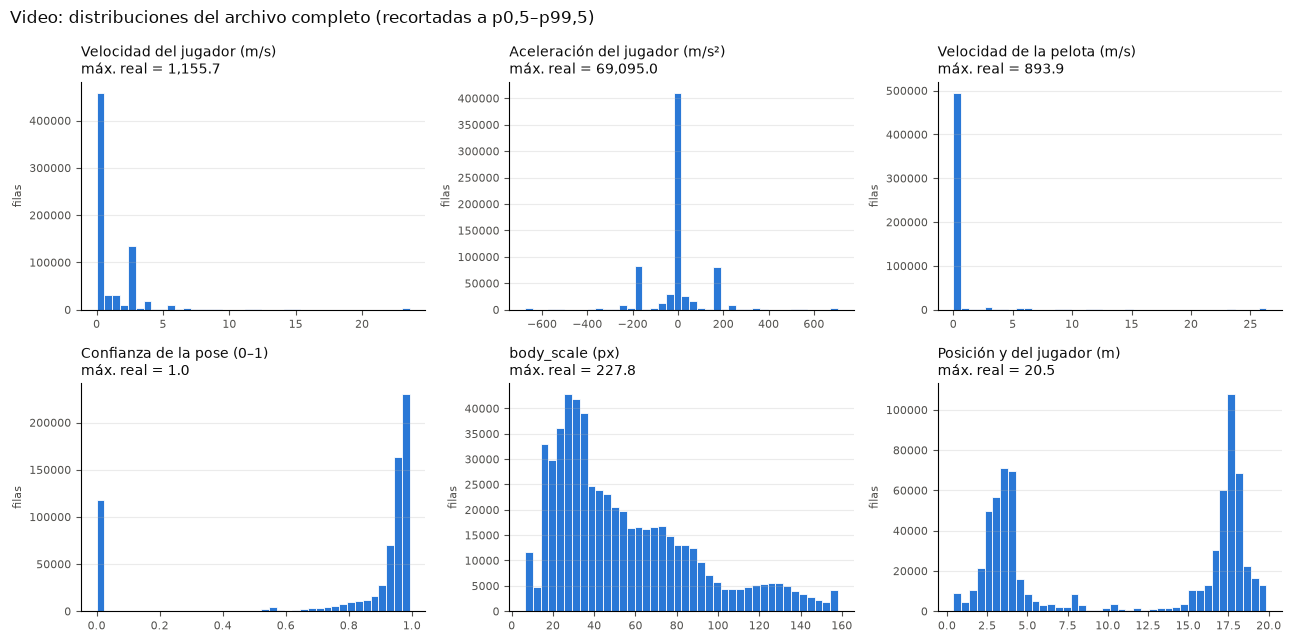

In [5]:
import matplotlib.pyplot as plt

VARIABLES_DIST = {
    'player_speed_mps': 'Velocidad del jugador (m/s)',
    'player_acceleration_mps2': 'Aceleración del jugador (m/s²)',
    'ball_speed_mps': 'Velocidad de la pelota (m/s)',
    'pose_confidence': 'Confianza de la pose (0–1)',
    'body_scale': 'body_scale (px)',
    'player_position_y': 'Posición y del jugador (m)',
}
dist = datos.leer_video(list(VARIABLES_DIST))
display(dist[list(VARIABLES_DIST)].describe(percentiles=[.01, .5, .99]).T.round(2))

COLOR, TINTA, TINTA_2 = '#2a78d6', '#0b0b0b', '#52514e'
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for eje, (col, titulo) in zip(ejes.flat, VARIABLES_DIST.items()):
    serie = dist[col].dropna()
    lo, hi = serie.quantile([0.005, 0.995])
    eje.hist(serie.clip(lo, hi), bins=40, color=COLOR, edgecolor='white', linewidth=0.6)
    eje.set_title(f'{titulo}\nmáx. real = {serie.max():,.1f}', fontsize=10, color=TINTA, loc='left')
    eje.tick_params(colors=TINTA_2, labelsize=8)
    eje.grid(axis='y', alpha=0.25)
    eje.spines[['top', 'right']].set_visible(False)
    eje.set_ylabel('filas', fontsize=8, color=TINTA_2)
fig.suptitle('Video: distribuciones del archivo completo (recortadas a p0,5–p99,5)', fontsize=12, color=TINTA, x=0.01, ha='left')
fig.tight_layout()
plt.show()

**Lectura**
- **Velocidad y aceleración del jugador:** son imposibles para una persona (máximos de 1.155,7 m/s y ±69.000 m/s²). El histograma muestra escalones discretos en 0, ~1,5 y ~3 m/s: es la cuantización de las posiciones (~5 cm) derivada frame a frame sin suavizar. Por eso se recalculan sobre la trayectoria suavizada (sección 1.8).
- **Velocidad de la pelota:** su mediana es 0 y su máximo 893,9 m/s; no sirve.
- **Confianza de la pose:** tiene un pico en 0 (frames sin pose) y el resto se concentra cerca de 0,95.
- **`body_scale`:** va de 3 a 228 px y está sesgada a la derecha según la distancia a la cámara, así que todo lo que se mide en píxeles debe normalizarse.
- **Posición `y`:** es bimodal, con un pico por cada fondo de la cancha.

### 1.2.4 Traza y formulario: tipos, faltantes y frecuencias

Las dos fuentes pequeñas se leen completas. En el formulario se omiten de las frecuencias las respuestas abiertas y los datos personales.

TRAZA (ambas canchas)


columna,ID_PARTIDO,ID_PUNTO,PUNTO_EQUIPO_1,PUNTO_EQUIPO_2,MARCADOR,ID_JUGADOR_1_EQUIPO_1,Equipo1_Banda1,ID_JUGADOR_2_EQUIPO_1,Equipo1_Banda2,ID_JUGADOR_1_EQUIPO_2,Equipo2_Banda1,ID_JUGADOR_2_EQUIPO_2,Equipo2_Banda2,EQUIPO_1_POSICION,EQUIPO_2_POSICION,POSICION_JUGADOR_1_EQUIPO_1,POSICION_JUGADOR_2_EQUIPO_1,POSICION_JUGADOR_1_EQUIPO_2,POSICION_JUGADOR_2_EQUIPO_2,cancha
tipo,int64,int64,int64,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,int64
no_nulos,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283,283
faltantes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
pct_faltante,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
distintos,27,13,2,2,59,20,4,19,4,16,4,17,4,1,1,2,2,3,4,2


Puntos por partido:


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,13.0,13.0,10.0,10.0,NaN,11.0,NaN,11.0,8.0,NaN,NaN,9.0,NaN,NaN,8.0,NaN,12.0,NaN,9.0,NaN,12.0,11.0,NaN,NaN,7.0,10.0,10.0
2,NaN,NaN,NaN,NaN,10.0,NaN,11.0,NaN,NaN,10.0,13.0,NaN,10.0,11.0,NaN,13.0,NaN,10.0,NaN,7.0,NaN,NaN,12.0,12.0,NaN,NaN,NaN


EQUIPO_1_POSICION: {'BOTTOM': 283}
POSICION_JUGADOR_1_EQUIPO_1: {'RIGHT': 163, 'LEFT': 120}
POSICION_JUGADOR_2_EQUIPO_2: {'RIGHT': 150, 'LEFT': 121, 'RIGTH': 12}
Equipo1_Banda1: {'Light_Blue': 98, 'Yellow': 97, 'Orange': 66, 'Dark_Blue': 22}

FORMULARIO


,tipo,no_nulos,faltantes,pct_faltante,distintos
columna,,,,,
RITMO_CARDIACO,object,12,17,58.62,12
COMENTARIOS,object,28,1,3.45,24
Puntos_Total,float64,27,2,6.90,21
Partidos_Jugados,float64,27,2,6.90,5
Puntos_Por_Partido,float64,27,2,6.90,24


,count,mean,std,min,25%,50%,75%,max
EDAD,29.0,20.3,2.9,18.0,19.0,19.0,21.0,30.0
SEMESTRE,29.0,5.0,2.0,3.0,4.0,4.0,6.0,10.0
ESTATURA,29.0,171.8,11.9,150.0,165.0,173.0,179.0,194.0
TALLA,29.0,69.1,16.7,40.0,60.0,69.0,80.0,107.0
Puntos_Total,27.0,19.1,9.1,2.0,13.0,19.0,23.5,41.0
Partidos_Jugados,27.0,5.1,1.2,2.0,4.5,5.0,6.0,7.0
Puntos_Por_Partido,27.0,3.6,1.4,0.5,3.1,3.8,4.6,5.9


GENERO: {'Masculino': 18, 'Femenino': 11}
EXPERIENCIA_PADEL: {'No': 16, 'Sí': 13}
TIEMPO_JUGANDO_PADEL: {'Menos de 6 meses': 22, 'Entre 6 meses y 1 año': 5, 'Más de 1 año': 2}
PRACTICA_OTRO_DEPORTE_RAQUETA: {'No': 14, 'Tenis': 9, 'Tenis de mesa': 3, 'Squash': 2, 'Otro': 1}
NIVEL_ACTUAL_PADEL: {'Principiante': 12, 'Primera vez': 11, 'Intermedio': 5, 'Avanzado': 1}
ESTADO_FISICO: {'Bueno': 19, 'Excelente': 5, 'Regular': 4, 'Malo': 1}
FRECUENCIA_DEPORTE: {'Más de 4 veces': 9, '1-2 veces': 9, '3-4 veces': 7, '0 veces': 3, 'No practico deportes': 1}
MANO_DOMINANTE: {'Derecha': 27, 'Izquierda': 2}
LESIONES_LY: {'No': 22, 'Sí': 7}


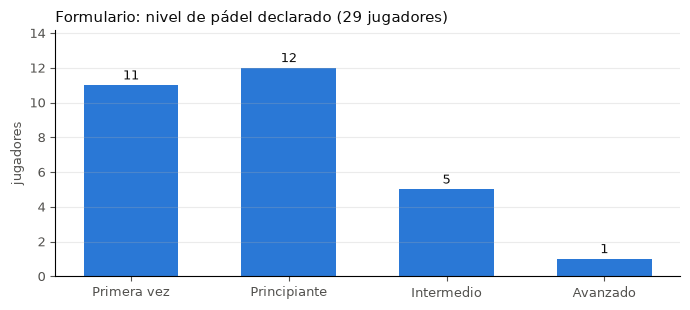

In [6]:
print('TRAZA (ambas canchas)')
display(datos.perfil_columnas(traza_cruda).T)
print('Puntos por partido:')
display(traza_cruda.groupby(['cancha', 'ID_PARTIDO']).size().rename('puntos').unstack(0).T)
for c in ['EQUIPO_1_POSICION', 'POSICION_JUGADOR_1_EQUIPO_1', 'POSICION_JUGADOR_2_EQUIPO_2', 'Equipo1_Banda1']:
    print(f'{c}:', traza_cruda[c].astype(str).str.strip().value_counts().to_dict())

print('\nFORMULARIO')
perfil_form = datos.perfil_columnas(form_crudo)
display(perfil_form[perfil_form['faltantes'] > 0])
display(form_crudo.select_dtypes('number').drop(columns=['CODIGO_ESTUDIANTE']).describe().T.round(1))
for c in ['GENERO', 'EXPERIENCIA_PADEL', 'TIEMPO_JUGANDO_PADEL', 'PRACTICA_OTRO_DEPORTE_RAQUETA', 'NIVEL_ACTUAL_PADEL',
          'ESTADO_FISICO', 'FRECUENCIA_DEPORTE', 'MANO_DOMINANTE', 'LESIONES_LY']:
    print(f'{c}:', form_crudo[c].value_counts(dropna=False).to_dict())

orden_nivel = ['Primera vez', 'Principiante', 'Intermedio', 'Avanzado']
nivel = form_crudo['NIVEL_ACTUAL_PADEL'].value_counts().reindex(orden_nivel, fill_value=0)
fig, eje = plt.subplots(figsize=(7, 3.2))
barras = eje.bar(nivel.index, nivel.values, color=COLOR, width=0.6)
eje.bar_label(barras, padding=2, fontsize=9, color=TINTA)
eje.set_ylim(0, nivel.max() * 1.18)
eje.set_title('Formulario: nivel de pádel declarado (29 jugadores)', fontsize=11, color=TINTA, loc='left')
eje.set_ylabel('jugadores', fontsize=9, color=TINTA_2)
eje.tick_params(colors=TINTA_2, labelsize=9)
eje.grid(axis='y', alpha=0.25)
eje.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Lectura**
- **Traza:** no tiene faltantes. El equipo 1 siempre está en BOTTOM y los lados aparecen con la errata `RIGTH`. Cada partido tiene entre 7 y 13 puntos.
- **Formulario:** solo tiene faltantes en `RITMO_CARDIACO` (descartada), `COMENTARIOS` y las 3 columnas de resultados (2 jugadores sin partidos). A diferencia de la versión CSV que leían los notebooks de entendimiento, en el Excel no aparece `#N/D` ni hay filas vacías de exportación.
- **Nivel:** el 79 % de los jugadores es principiante o juega por primera vez.
- **Mano:** solo hay 2 zurdos.

### 1.2.5 Relación entre las fuentes: nombres y llaves sin corregir

Antes de construir la tabla de equivalencias (1.3) se mide cuánto coinciden las fuentes tal como vienen: nombres exactos tras quitar tildes, espacios y mayúsculas, y la llave `(partido, punto)` del video contra `(ID_PARTIDO, ID_PUNTO)` de la traza.

In [7]:
nombres_form = set(form_crudo['NOMBRE'].map(idn.normalizar_nombre)) - {''}
nombres_traza_n = set(pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
                      .map(idn.normalizar_nombre)) - {''}
nombres_video_n = {idn.normalizar_nombre(n) for n in video['nombre_norm'].unique() if not idn.es_generico(n)}
display(pd.DataFrame([
    {'comparación': a, 'distintos_A': len(x), 'distintos_B': len(y), 'coincidencias_exactas': len(x & y)}
    for a, x, y in [('traza vs video', nombres_traza_n, nombres_video_n),
                    ('traza vs formulario', nombres_traza_n, nombres_form),
                    ('video vs formulario', nombres_video_n, nombres_form)]
]))
print('Nombres de la traza sin coincidencia exacta en el formulario:', sorted(nombres_traza_n - nombres_form))

llaves_video = set(map(tuple, video[['partido', 'punto']].drop_duplicates().to_numpy()))
llaves_traza = set(map(tuple, traza_cruda[['ID_PARTIDO', 'ID_PUNTO']].to_numpy()))
print(f'Llaves (partido, punto): video {len(llaves_video)} | traza {len(llaves_traza)} | en ambas {len(llaves_video & llaves_traza)}')
print('En el video y no en la traza:', sorted((int(a), int(b)) for a, b in llaves_video - llaves_traza))

,comparación,distintos_A,distintos_B,coincidencias_exactas
0,traza vs video,30,30,30
1,traza vs formulario,30,29,19
2,video vs formulario,30,29,19


Nombres de la traza sin coincidencia exacta en el formulario: ['alejandra briget deza cespedes', 'angie vanessa gonzalez farfan', 'isabella arenas', 'jose fabian garcia', 'juan andres ordonez vanegas', 'juan pablo vanegas herrera', 'laura sofia rodriguez gonzalez', 'miguel medina', 'nikol sofia avendano suarez', 'sofia santander', 'valentina rodriguez']
Llaves (partido, punto): video 272 | traza 283 | en ambas 268
En el video y no en la traza: [(7, 11), (11, 12), (23, 9), (32, 13)]


**Lectura**
- **Traza contra video:** los nombres coinciden 30 de 30, pero eso no garantiza que cada etiqueta esté en el jugador correcto; la sección 1.7 encuentra los partidos 8, 17 y 34 mal etiquetados.
- **Traza contra formulario:** solo coinciden 19 nombres. Ocho jugadores tienen variantes de nombre y 3 no llenaron el formulario; se resuelve en 1.3.
- **Llaves:** 268 puntos están en ambas fuentes.

### 1.2.6 Preguntas iniciales y su respuesta

Los notebooks de entendimiento cerraban con estas preguntas. Esta tabla las responde con lo encontrado en el resto de la Fase 1.

| Pregunta | Respuesta | Dónde |
|---|---|---|
| ¿Qué representa cada fila? | Video: un jugador en un frame. Traza: un punto. Formulario: un jugador. No hay filas repetidas en la llave del video. | 1.2.2 |
| ¿En qué sistema de coordenadas están las posiciones y en qué unidad? | Metros, por homografía a la cancha: `x` ∈ [0, 10], `y` ∈ [0, 20] y red en `y = 10`. BOTTOM está en `y > 10` y RIGHT en `x > 5` para ambos equipos (D13). Excepciones: partidos 17 y 27. | 1.6, 1.7 |
| ¿Cómo se codifican los booleanos y los indicadores de implausibilidad? | Como texto `True`/`False`. Los `*_implausible` solo existen en los partidos 10, 13 y 39; se descartan. | 1.2.2 |
| ¿Hay identificadores que separen partido, punto, jugador y video sin ambigüedad? | Track = `(partido, punto, player_id)`; jugador = `codigo` de 6 dígitos (D8). El nombre nunca es llave. | 1.3, 1.7 |
| ¿Sirven los nombres para unir las fuentes? | Solo a través de la tabla de equivalencias (D9). Video y traza coinciden en el texto, pero 3 partidos tienen etiquetas incorrectas (D12). | 1.3, 1.7 |
| ¿Cómo se construyen `partido` y `punto` y coinciden con la traza? | Son los mismos números de la traza: 268 puntos coinciden. 4 videos no tienen traza (D15) y 15 puntos de la traza no tienen video. Supuesto: la numeración es la misma. | 1.2.5, 1.7 |
| ¿Cómo tratar `#N/D`, faltantes, filas implausibles y pose ausente? | El Excel actual no tiene `#N/D`. Los faltantes del formulario se imputan (D4) y los de pose se interpolan en huecos de ≤5 frames. | 1.5, 1.8 |
| ¿En qué zona horaria está el formulario? | No importa: `Marca temporal` no se usa. | 1.5 |

### 1.2.7 Resumen de hallazgos y su tratamiento

| Tema | Hallazgo | Tratamiento |
|---|---|---|
| Grano | Una fila es un jugador en un frame; no hay duplicados en la llave. | Base del pipeline |
| fps | Variable por video: 24, 30 y 60 fps (algunos 59,9). El partido 32 tiene 300 frames por punto con fps de 11,8 a 39,9. | fps = 1/`duration` por punto (D2) |
| Velocidad y aceleración | Muy ruidosas, con máximos imposibles. | Recalcular sobre la trayectoria suavizada (sección 1.8) |
| Pose y raqueta | Cerca del 20 % de faltantes; según el partido va de 0 % a 100 %. | Interpolar huecos de ≤5 frames y guardar `pose_coverage` (1.8) |
| Pelota | Velocidad con mediana 0 y máximos imposibles. `player_hits_ball` es verdadero en el 0,3 % de las filas. | Se descarta toda la familia (el uso de `player_hits_ball` está por confirmar) |
| `team` | 8,3 % de faltantes; 100 % en los partidos 8 y 34. | Completar con el valor del jugador (1.8) |
| `*_implausible` | Solo en los partidos 10, 13 y 39. | No se usan |
| Nombres | Coinciden entre traza y video, pero no con el formulario. | Tabla de equivalencias (1.3) e identidad por track (1.7) |
| Formulario | 29 filas; 3 jugadores sin formulario y 2 personas que no juegan. | Imputación (1.5) |

## 1.3 Identidad de los jugadores: códigos y nombres

**Objetivo:** una tabla única de equivalencias que lleve cualquier nombre de cualquier fuente a su nombre canónico y a su `codigo`.

**Decisiones**
- **D4 (códigos):** el equipo entregó los códigos de quienes no llenaron el formulario: Alejandra Briget Deza Céspedes (407710), Juan Pablo Vanegas Herrera (356629) y Laura Sofía Rodríguez González (324764).
- **D8:** todos los códigos tienen 6 dígitos. Jorge García pasa de 99999 a `099999` (se antepone un 0) y José Fabián García Camargo pasa de 1075684546 a `107568` (primeros 6 dígitos). El código se guarda como texto para conservar el cero inicial.
- **D9:** las variantes de nombre son el mismo jugador (no se separan en seguras y dudosas). Se usa el nombre completo con dos apellidos cuando alguna fuente lo tiene. Ejemplos: `Isabella Arenas` → *Isabella Arenas González* y `Sofia Santander` → *Ana Sofía Santander Prieto*.
- **Proceso recurrente (Teams):** si un nombre queda sin cruzar, se lista aquí para buscarlo en Teams; luego se agrega a `NOMBRES_CANONICOS` en `src/identidades.py` y se vuelve a correr.

In [8]:
codigos = idn.tabla_codigos(form_crudo)
nombres_traza = pd.concat([traza_cruda[f'ID_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS])
equivalencias = idn.tabla_equivalencias(
    {'formulario': form_crudo['NOMBRE'], 'traza': nombres_traza, 'video': video['nombre_norm'].unique()}, codigos)

print('Códigos corregidos (D8):')
display(form_crudo.loc[form_crudo['CODIGO_ESTUDIANTE'].astype(str).isin(idn.CORRECCIONES_CODIGO), ['NOMBRE', 'CODIGO_ESTUDIANTE']]
        .assign(codigo=lambda d: d['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo)))
print('Cruces por alias (variantes del mismo nombre, D9):')
display(equivalencias[equivalencias['tipo_cruce'] == 'alias'])

resumen_cruce = equivalencias.pivot_table(index='fuente', columns='tipo_cruce', values='nombre_original', aggfunc='count', fill_value=0)
display(resumen_cruce)
pendientes_teams = idn.sin_cruzar(equivalencias)
print(f'Nombres sin cruzar (buscar en Teams): {len(pendientes_teams)}')
display(pendientes_teams)
print('Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):')
print([n for n in codigos['nombre'] if len(n.split()) == 2])
datos.guardar_tabla(equivalencias, 'equivalencias_nombres')

Códigos corregidos (D8):


,NOMBRE,CODIGO_ESTUDIANTE,codigo
12,Jorge Garcia,99999,099999
13,Jose Fabian Garcia Camargo,1075684546,107568


Cruces por alias (variantes del mismo nombre, D9):


,fuente,nombre_original,nombre,tipo_cruce,codigo
6,traza,Sofia Santander,Ana Sofía Santander Prieto,alias,326450
7,video,sofia santander,Ana Sofía Santander Prieto,alias,326450
14,formulario,Angie vanessa gonzalez 0,Angie Vanessa González Farfan,alias,350977
33,traza,Isabella Arenas,Isabella Arenas González,alias,350430
34,video,isabella arenas,Isabella Arenas González,alias,350430
45,traza,Jose Fabian Garcia,Jose Fabian Garcia Camargo,alias,107568
46,video,jose fabian garcia,Jose Fabian Garcia Camargo,alias,107568
47,formulario,Juan Andrés Ordóñez,Juan Andrés Ordóñez Vanegas,alias,196393
75,traza,Miguel Medina,Miguel Medina Velez,alias,351752
76,video,miguel medina,Miguel Medina Velez,alias,351752


tipo_cruce,alias,exacto
fuente,,
formulario,3,26
traza,5,25
video,5,25


Nombres sin cruzar (buscar en Teams): 0


,fuente,nombre_original,nombre,tipo_cruce,codigo


Nombres canónicos con un solo apellido (ninguna fuente trae el nombre completo):
['Jeronimo Coy', 'Jorge García', 'Juliana Gómez', 'Marcela Velásquez', 'Miguel Delgado']


WindowsPath('C:/Users/majos/OneDrive - Universidad de la Sabana/UNIVERSIDAD/SEMESTRE 5/Analitica de datos/Proyecto Analitica/Proyecto_final_analitica/data/interim/equivalencias_nombres.csv')

**Resultado**
- Hay 32 personas con código: los 29 del formulario y los 3 de la D4. De ellas, 30 juegan en la traza.
- Ningún nombre de ninguna fuente queda sin cruzar, así que hoy no hay pendientes para Teams. Ocho jugadores tienen variantes de nombre, que suman 13 nombres cruzados por alias.
- Cinco jugadores tienen un solo apellido en todas las fuentes (por ejemplo, Juliana Gómez y Miguel Delgado). Se mantienen así; si se quiere el segundo apellido, hay que buscarlo en Teams.
- Salida: `data/interim/equivalencias_nombres.csv`.

## 1.4 Traza de partidos

**Objetivo:** dejar la traza limpia por punto, con los códigos de los cuatro jugadores, y su versión larga jugador × punto (`participaciones`).

**Decisiones**
- **D3:** la variable objetivo es el ganador del punto, `PUNTO_EQUIPO_1`.
- **D13:** se corrige la errata `RIGTH` → `RIGHT` (partido 34). La convención de lados se verificó contra el video (sección 1.7): `BOTTOM` está en `y > 10` y, para ambos equipos, `RIGHT` está en `x > 5`.
- **Lado de cancha:** el equipo 1 siempre está en BOTTOM. Se incluye como variable de control, sin sacar conclusiones fuertes.

In [9]:
print('Controles de consistencia sobre la traza cruda:')
display(fuentes.validar_traza(traza_cruda))
lados_crudos = pd.concat([traza_cruda[f'POSICION_JUGADOR_{j}_EQUIPO_{e}'] for e, j in fuentes.SLOTS]).str.strip().value_counts()
print('Valores de lado en la traza cruda:', lados_crudos.to_dict())

traza = fuentes.limpiar_traza(traza_cruda, codigos)
participaciones = fuentes.traza_larga(traza)
puntos_traza = fuentes.tabla_puntos_traza(traza)
display(datos.comparar(datos.resumen_tabla(traza_cruda, 'traza cruda'), datos.resumen_tabla(traza, 'traza limpia'),
                       datos.resumen_tabla(participaciones, 'participaciones (jugador × punto)')))
assert participaciones['codigo'].notna().all()

finales = traza.groupby('ID_PARTIDO').agg(cancha=('cancha', 'first'), puntos=('ID_PUNTO', 'size'), marcador_final=('MARCADOR', 'last'))
print('Todos los partidos terminan cuando un equipo llega a 7:',
      finales['marcador_final'].str.split('-').map(lambda m: max(map(int, m)) == 7).all())
display(finales.T)

print(f"Balance de la variable objetivo: el equipo 1 gana el {traza['PUNTO_EQUIPO_1'].mean():.1%} de {len(traza)} puntos")
sin_traza = sorted(set(programacion['Partido']) - set(traza['ID_PARTIDO']))
print(f'Partidos programados sin traza ({len(sin_traza)}): {sin_traza}')

Controles de consistencia sobre la traza cruda:


,filas con problema
PUNTO_EQUIPO_1 + PUNTO_EQUIPO_2 != 1,0
partido-punto duplicado,0
MARCADOR distinto del acumulado,0
ID_PUNTO no consecutivo,0
lado LEFT/RIGHT cambia dentro del partido,0


Valores de lado en la traza cruda: {'LEFT': 566, 'RIGHT': 554, 'RIGTH': 12}


,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,traza cruda,283,20,0,0.0
1,traza limpia,283,28,0,0.0
2,participaciones (jugador × punto),1132,12,0,0.0


Todos los partidos terminan cuando un equipo llega a 7: True


ID_PARTIDO,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
cancha,1,1,1,1,2,1,2,1,1,2,2,1,2,2,1,2,1,2,1,2,1,1,2,2,1,1,1
puntos,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
marcador_final,6-7,6-7,3-7,3-7,3-7,7-4,4-7,4-7,1-7,3-7,6-7,7-2,3-7,7-4,1-7,7-6,5-7,3-7,7-2,0-7,7-5,7-4,7-5,5-7,0-7,7-3,3-7


Balance de la variable objetivo: el equipo 1 gana el 43.1% de 283 puntos
Partidos programados sin traza (12): [2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36, 38]


**Resultado**
- La traza pasa todos los controles: un ganador por punto, sin duplicados, marcador igual al acumulado, puntos consecutivos y lados fijos dentro de cada partido.
- Todos los partidos terminan cuando un equipo llega a 7.
- El equipo 1 gana el 43,1 % de los puntos, así que las clases están moderadamente balanceadas.
- Los 12 partidos programados sin traza (2, 4, 6, 12, 15, 19, 21, 22, 30, 33, 36 y 38) no tienen tampoco video y no entran al análisis.

## 1.5 Formulario de jugadores

**Objetivo:** una fila por jugador con las variables fijas usables, codificadas, más los 3 jugadores imputados.

**Decisiones**
- **D1:** `TALLA` es el peso en kg. IMC = peso / (estatura en m)².
- **D4 (imputación):** los 3 jugadores sin formulario se imputan con datos de su mismo sexo.
  - Continuas (edad, estatura y peso): media. A las dos mujeres se les suma ruido N(0, sd de las mujeres) con semilla fija y se recorta al rango observado.
  - Ordinales: mediana; si cae entre dos categorías, se toma la inferior.
  - Categóricas: moda.
  - Las filas imputadas llevan `imputado = True`.
- **D5:** resuelta. La fila de 152 cm y 48 kg corresponde a Ana Catalina Suárez Caballero (código 337448) y ya viene con nombre en el formulario actual.
- **D11:** codificación ordinal (0 = menor):
  - nivel: Primera vez < Principiante < Intermedio < Avanzado.
  - tiempo jugando: <6 meses < 6–12 meses < >1 año.
  - experiencia: No < Sí.
  - estado físico: Malo < Regular < Bueno < Excelente.
  - frecuencia: 0 < 1–2 < 3–4 < >4 veces por semana.

  Como `TIEMPO_JUGANDO_PADEL` es categórica, se imputa como ordinal (mediana) y no con la media.
- **D10 (por confirmar):** en `FRECUENCIA_DEPORTE`, las respuestas «0 veces» y «No practico deportes» se unen en el nivel 0.
- **Descartadas:** ciudad, programa, semestre, razón y objetivo de participación, interés y clases de pádel, desayuno, género musical, comentarios y `RITMO_CARDIACO`.
- **Fuga de datos:** `Puntos_Total`, `Partidos_Jugados` y `Puntos_Por_Partido` no entran a la tabla; solo se usan abajo para validar la traza.

In [10]:
jugadores_base = fuentes.limpiar_formulario(form_crudo)
jugadores = fuentes.agregar_derivadas_jugadores(fuentes.imputar_sin_formulario(jugadores_base, datos.SEMILLA))
display(datos.comparar(datos.resumen_tabla(form_crudo, 'formulario crudo'),
                       datos.resumen_tabla(jugadores_base, 'formulario limpio'),
                       datos.resumen_tabla(jugadores, 'jugadores (con imputados y derivadas)')))

print('Jugadores imputados (D4):')
display(jugadores[jugadores['imputado']])
print('Rangos de las continuas:')
display(jugadores[['edad', 'estatura_cm', 'peso_kg', 'imc']].astype(float).describe().T.round(1))

juegan = set(participaciones['codigo'])
print(f'Jugadores de la traza con datos: {len(juegan & set(jugadores["codigo"]))} de {len(juegan)}')
print('En el formulario pero sin partidos con traza:', jugadores.loc[~jugadores['codigo'].isin(juegan), 'nombre'].tolist())
datos.guardar_tabla(jugadores, 'jugadores')

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,formulario crudo,29,30,24,2.76
1,formulario limpio,29,15,0,0.00
2,jugadores (con imputados y derivadas),32,20,0,0.00


Jugadores imputados (D4):


,codigo,nombre,genero,mujer,edad,estatura_cm,peso_kg,imc,mano_dominante,zurdo,nivel_padel,tiempo_jugando_padel,experiencia_padel,otro_deporte_raqueta,practica_otra_raqueta,estado_fisico,frecuencia_deporte,lesiones_ly,lesion_ultimo_anio,imputado
0,407710,Alejandra Briget Deza Céspedes,Femenino,1,19,162,40.0,15.24,Derecha,0,1,0,0,No,0,2,2,No,0,True
18,356629,Juan Pablo Vanegas Herrera,Masculino,0,20,179,76.8,23.97,Derecha,0,1,0,0,Tenis,1,2,2,No,0,True
22,324764,Laura Sofía Rodríguez González,Femenino,1,24,165,51.9,19.06,Derecha,0,1,0,0,No,0,2,2,No,0,True


Rangos de las continuas:


,count,mean,std,min,25%,50%,75%,max
edad,32.0,20.4,2.9,18.0,19.0,19.0,21.2,30.0
estatura_cm,32.0,171.5,11.6,150.0,164.5,173.0,179.0,194.0
peso_kg,32.0,67.9,17.0,40.0,55.5,68.5,80.0,107.0
imc,32.0,22.8,3.9,15.2,20.4,22.5,25.0,32.8


Jugadores de la traza con datos: 30 de 30
En el formulario pero sin partidos con traza: ['Juan Camilo Sánchez', 'Karol Valentina Carranza Gantiva']


WindowsPath('C:/Users/majos/OneDrive - Universidad de la Sabana/UNIVERSIDAD/SEMESTRE 5/Analitica de datos/Proyecto Analitica/Proyecto_final_analitica/data/interim/jugadores.csv')

**Validación con las columnas de fuga.** Se recalcula desde la traza la suma de puntos que hizo el equipo de cada jugador en sus partidos y se compara con `Puntos_Total` y `Partidos_Jugados`. No entran a ningún modelo.

In [11]:
puntos_traza_jugador = (participaciones.groupby(['codigo', 'partido'])['gano_punto'].sum()
                        .groupby('codigo').agg(puntos_desde_traza='sum', partidos_con_traza='size'))
validacion = (form_crudo[['NOMBRE', 'Puntos_Total', 'Partidos_Jugados']]
              .assign(codigo=form_crudo['CODIGO_ESTUDIANTE'].map(idn.normalizar_codigo))
              .merge(puntos_traza_jugador, on='codigo', how='left'))
validacion['coincide_puntos'] = validacion['Puntos_Total'] == validacion['puntos_desde_traza']
validacion['coincide_partidos'] = validacion['Partidos_Jugados'] == validacion['partidos_con_traza']
con_dato = validacion['Puntos_Total'].notna()
print(f"Jugadores con Puntos_Total: {con_dato.sum()} | coincide con la traza: {validacion.loc[con_dato, 'coincide_puntos'].sum()}"
      f" | Partidos_Jugados coincide: {validacion.loc[con_dato, 'coincide_partidos'].sum()}")
print('Diferencias:')
display(validacion[con_dato & ~(validacion['coincide_puntos'] & validacion['coincide_partidos'])])

Jugadores con Puntos_Total: 27 | coincide con la traza: 27 | Partidos_Jugados coincide: 2
Diferencias:


,NOMBRE,Puntos_Total,Partidos_Jugados,codigo,puntos_desde_traza,partidos_con_traza,coincide_puntos,coincide_partidos
0,Ana Sofía Santander Prieto,4.0,5.0,326450,4.0,2.0,True,False
1,Andrés Felipe Santafe Buitrago,41.0,7.0,352369,41.0,6.0,True,False
2,Angel Santiago Toribio Godoy,27.0,6.0,349345,27.0,5.0,True,False
3,Angie vanessa gonzalez 0,22.0,6.0,350977,22.0,4.0,True,False
4,Antonio Benitez Rueda,24.0,7.0,334943,24.0,4.0,True,False
5,David Jeronimo Rojas Gutierrez,12.0,5.0,376184,12.0,4.0,True,False
6,David Neisa Tello,17.0,6.0,349342,17.0,4.0,True,False
7,Gabriel Armando González Sosa,25.0,5.0,323614,25.0,4.0,True,False
8,Gabriel López Acosta,20.0,5.0,367769,20.0,4.0,True,False
9,Isabella Arenas González,2.0,4.0,350430,2.0,2.0,True,False


**Resultado**
- La tabla de jugadores tiene 32 filas (29 del formulario más 3 imputados) y sus variables usables no tienen faltantes.
- Los 30 jugadores de la traza tienen datos. Juan Camilo Sánchez y Karol Carranza no juegan ningún partido con traza.
- **Validación:** `Puntos_Total` coincide con la traza en los 27 jugadores que tienen el dato, lo que confirma la traza y el cruce de códigos. En cambio, `Partidos_Jugados` es mayor que los partidos con traza: cuenta partidos programados sin traza que no aportan puntos al total.
- Salida: `data/interim/jugadores.csv`.

## 1.6 Video: diagnóstico de calidad por punto

**Objetivo:** detectar automáticamente, para cada punto de video, los problemas que afectan la limpieza y el modelado. La detección funciona igual para cualquier video nuevo.

**Decisiones**
- **D6:** los CSV de video se reciben ya generados; no se usa el pipeline de visión del profesor.
- **D7:** el punto 10 del partido 5 es una copia exacta del punto 9. Se conserva el video como punto 9 y el punto 10 queda sin video. La regla general es conservar el de menor número; cualquier duplicado nuevo se revisa con el equipo.
- Banderas que se calculan por punto:

| Bandera | Regla |
|---|---|
| `y_invalida` | `y` = `x` en más del 95 % de las filas |
| `sin_pose` | 0 % de frames con pose |
| `y_top_distorsionada` | mediana de `y` del equipo `top` > 10 m |
| `fps_no_estandar` | fps distinto de 24, 30 o 60 |
| `duplicado_de_punto` | firma idéntica a otro punto del mismo partido |

In [12]:
diagnostico = vid.diagnosticar_puntos(video)
banderas = ['y_invalida', 'sin_pose', 'y_top_distorsionada', 'fps_no_estandar']
por_partido = diagnostico.groupby('partido').agg(
    puntos=('punto', 'size'), fps=('fps', 'median'), pct_pose_medio=('pct_pose', 'mean'),
    pct_team_faltante=('pct_team_faltante', 'mean'), pct_fuera_cancha=('pct_fuera_cancha', 'mean'),
    tracks_genericos=('tracks_genericos', 'sum'), duplicados=('duplicado_de_punto', 'count'),
    **{b: (b, 'sum') for b in banderas}).round(1)
display(por_partido)
print('Partidos con alguna bandera o duplicado:')
display(por_partido[(por_partido[banderas + ['duplicados']] > 0).any(axis=1)])

,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose,y_top_distorsionada,fps_no_estandar
partido,,,,,,,,,,,
1,11,60.0,59.1,5.4,0.9,3,0,0,0,0,0
3,8,60.0,81.8,3.6,0.1,4,0,0,0,0,0
5,10,24.0,92.7,1.4,0.3,4,1,0,0,0,0
7,11,24.0,87.3,0.2,0.2,1,0,0,0,0,0
8,8,30.0,100.0,100.0,2.1,0,0,0,0,0,0
9,11,30.0,93.0,7.0,0.3,5,0,0,0,0,0
10,11,60.0,92.2,12.6,2.2,0,0,0,0,0,0
11,12,30.0,96.0,0.9,0.2,5,0,0,0,0,0
13,7,30.0,98.2,15.2,0.1,0,0,0,0,0,0


Partidos con alguna bandera o duplicado:


,puntos,fps,pct_pose_medio,pct_team_faltante,pct_fuera_cancha,tracks_genericos,duplicados,y_invalida,sin_pose,y_top_distorsionada,fps_no_estandar
partido,,,,,,,,,,,
5,10,24.0,92.7,1.4,0.3,4,1,0,0,0,0
17,9,30.0,0.0,60.9,4.9,79,0,9,9,0,0
23,9,24.0,82.8,0.1,3.1,1,0,0,0,1,0
27,9,60.0,68.0,0.0,0.0,3,0,0,0,9,0
32,13,21.6,81.3,0.5,6.0,3,0,0,0,0,13


**Resultado: partidos con problemas de calidad**

| Partido | Problema | Consecuencia para el análisis |
|---|---|---|
| 5 | El punto 10 es una copia del punto 9 | El punto 10 queda sin video (D7) |
| 8 y 34 | Solo se detecta la pareja del fondo BOTTOM (cámara de media cancha) y `team` está vacío | No hay video del equipo 2 |
| 17 | `y` es copia de `x` y no hay pose en ningún frame; las etiquetas son `Jugador 1–4` | Solo sirven las variables basadas en `x` y en el tiempo |
| 23, punto 3 | La mediana de `y` del equipo top es 13 m (punto con 3 tracks) | Revisar en la limpieza |
| 27 | El equipo top aparece en `y` ≈ 15 m (homografía desplazada); `team` sí es correcto | La profundidad del equipo top no es confiable |
| 32 | 300 frames por punto con fps de 11,8 a 39,9 | Calcular el fps por punto (D2) |

## 1.7 Video: cruce con la traza e identidad de cada track

**Objetivo:** asignar a cada track `(partido, punto, player_id)` el `codigo` del jugador, de acuerdo con la traza.

**Decisiones**
- **D12:** se confía en la etiqueta de nombre del video si en el partido al menos el 50 % de las filas tiene nombres de la alineación de la traza y al menos el 80 % concuerda con la casilla (fondo, lado) que indica la traza.
  - Si no se cumple, la identidad se asigna **por posición contra la traza**. Para el fondo se usa `team` (o `y > 10` cuando `team` falta) y para el lado `x > 5`.
  - Se asigna de forma codiciosa: cada casilla recibe el track con mayor filas × p(fondo) × p(lado).
- **D14:** los tracks genéricos (`Player_N`) y los que quedan sin casilla compatible se descartan de la identidad.
- **D15:** los 4 puntos de video sin traza (7-11, 11-12, 23-9 y 32-13) se excluyen, porque según la traza esos partidos ya habían terminado. Supuesto: la numeración de puntos del video es la misma de la traza.

In [13]:
tracks = vid.resumir_tracks(video, diagnostico)
metodo_partido = vid.concordancia_por_partido(tracks, participaciones, diagnostico)
print('Concordancia de las etiquetas de nombre con la traza, por partido:')
display(metodo_partido)

identidades = vid.asignar_identidades(tracks, participaciones, diagnostico, metodo_partido)
print('Tracks y filas por resultado de la asignación:')
display(identidades.groupby(['conservar', 'metodo', 'motivo'], dropna=False)
        .agg(tracks=('filas', 'size'), filas=('filas', 'sum')).reset_index())
etq = identidades[identidades['metodo'] == 'etiqueta']
print(f"Con método etiqueta, el {np.average(etq['concuerda_posicion'].astype(float), weights=etq['filas']):.1%} "
      'de las filas también concuerda con la posición de la traza.')

Concordancia de las etiquetas de nombre con la traza, por partido:


,partido,filas,pct_filas_en_alineacion,pct_concordancia_posicion,metodo
0,1,75217.0,99.8,100.0,etiqueta
1,3,54222.0,100.0,100.0,etiqueta
2,5,12734.0,98.6,100.0,etiqueta
3,7,9137.0,100.0,100.0,etiqueta
4,8,6850.0,0.0,NaN,posicion
5,9,15487.0,99.4,96.9,etiqueta
6,10,27762.0,100.0,100.0,etiqueta
7,11,13606.0,99.7,100.0,etiqueta
8,13,14089.0,100.0,100.0,etiqueta
9,14,33254.0,99.0,97.4,etiqueta


Tracks y filas por resultado de la asignación:


,conservar,metodo,motivo,tracks,filas
0,False,NaN,punto sin traza,16,4044
1,False,NaN,sin casilla libre compatible,47,3300
2,False,NaN,track genérico sin identidad,105,3772
3,False,NaN,video duplicado del punto 9,4,1932
4,True,etiqueta,NaN,952,673335
5,True,posicion,NaN,77,32553


Con método etiqueta, el 99.0% de las filas también concuerda con la posición de la traza.


**Partidos asignados por posición.** La tabla cruza la etiqueta original del video con la identidad asignada (número de puntos).

In [14]:
reasignados = identidades[identidades['conservar'] & (identidades['metodo'] == 'posicion')]
for p, g in reasignados.groupby('partido'):
    print(f'\nPartido {p}:')
    display(pd.crosstab(g['etiqueta_video'], g['nombre']))


Partido 8:


nombre,Angel Santiago Toribio Godoy,Mariana Alfonso Forero
etiqueta_video,,
david neisa tello,2,6
jose fabian garcia,6,2



Partido 17:


nombre,Isabella Arenas González,Jeronimo Coy,Juliana Gómez,Luis Felipe Cuellar Santamaria
etiqueta_video,,,,
jugador 1,0,0,9,0
jugador 2,9,0,0,0
jugador 3,0,9,0,0
jugador 4,0,0,0,9



Partido 34:


nombre,Alejandra Briget Deza Céspedes,David Neisa Tello,Jeronimo Coy,Jose Fabian Garcia Camargo
etiqueta_video,,,,
alejandra briget deza cespedes,0,2,0,0
david neisa tello,11,0,0,0
jeronimo coy,0,0,1,0
jose fabian garcia,0,0,0,11


**Tabla de puntos** (una fila por punto): une la traza y el video e indica el estado del video y cuántos jugadores quedaron identificados por equipo.

In [15]:
puntos = vid.tabla_puntos(puntos_traza, diagnostico, identidades)
participaciones = vid.enlazar_participaciones(participaciones, identidades)

display(datos.comparar(datos.resumen_tabla(puntos, 'puntos'), datos.resumen_tabla(participaciones, 'participaciones'),
                       datos.resumen_tabla(identidades, 'identidades_video')))
print('Estado del video por punto:', puntos['estado_video'].value_counts().to_dict())
disp = puntos[puntos['estado_video'] == 'disponible']
print('Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):')
display(pd.crosstab(disp['identificados_e1'], disp['identificados_e2']))

cobertura_partido = puntos[puntos['en_traza']].groupby('partido').agg(
    puntos_traza=('punto', 'size'), con_video=('estado_video', lambda s: (s == 'disponible').sum()),
    equipos_completos=('equipos_completos', 'sum'))
display(cobertura_partido.T)

for nombre, tabla in [('identidades_video', identidades), ('puntos', puntos), ('participaciones', participaciones)]:
    print('Guardado:', datos.guardar_tabla(tabla, nombre).relative_to(RAIZ))

,tabla,filas,columnas,celdas_faltantes,pct_faltante
0,puntos,287,32,558,6.08
1,participaciones,1132,15,206,1.21
2,identidades_video,1201,21,2312,9.17


Estado del video por punto: {'disponible': 267, 'sin video': 15, 'video sin traza': 4, 'duplicado': 1}
Puntos con video disponible por jugadores identificados (equipo 1 × equipo 2):


identificados_e2,0,1,2
identificados_e1,,,
2,16,7,244


partido,1,3,5,7,8,9,10,11,13,14,16,17,18,20,23,24,25,26,27,28,29,31,32,34,35,37,39
puntos_traza,13,13,10,10,10,11,11,11,8,10,13,9,10,11,8,13,12,10,9,7,12,11,12,12,7,10,10
con_video,11,8,9,10,8,11,11,11,7,9,11,9,10,10,8,13,12,10,9,7,12,11,12,11,7,10,10
equipos_completos,11,8,9,10,0,11,11,11,7,9,11,9,10,10,7,13,12,10,6,7,12,11,12,0,7,10,10


Guardado: data\interim\identidades_video.csv
Guardado: data\interim\puntos.csv
Guardado: data\interim\participaciones.csv


**Resultado**
- Las etiquetas de nombre son confiables en 24 de los 27 partidos: con ellas, el 99 % de las filas concuerda con la casilla de la traza.
- Los partidos 8, 17 y 34 se reasignan por posición:
  - **8:** el video tenía los nombres del partido 34. Los dos jugadores del fondo BOTTOM son Angel Toribio (RIGHT) y Mariana Alfonso (LEFT).
  - **17:** `Jugador 1–4` corresponden a Juliana Gómez (top-left), Isabella Arenas (top-right), Jerónimo Coy (bottom-left) y Luis Felipe Cuéllar (bottom-right).
  - **34:** el track etiquetado «David Neisa» está en BOTTOM-LEFT, así que es Alejandra Deza; los pocos frames del fondo TOP corresponden a David Neisa y Jerónimo Coy.
- De los 283 puntos de la traza, 267 tienen video disponible. En ellos, 1.029 de las 1.068 participaciones jugador × punto posibles tienen track.
- 244 puntos tienen los dos equipos completos, 16 solo tienen al equipo BOTTOM (partidos 8 y 34) y 7 tienen 2 + 1 jugadores.
- Salidas: `data/interim/identidades_video.csv`, `data/interim/puntos.csv` y `data/interim/participaciones.csv`.

## 1.8 Limpieza del video frame × jugador — *pendiente*

**Objetivo:** una tabla limpia frame × jugador solo con los tracks conservados en la sección 1.7 (`identidades_video.conservar`). Las funciones irán en `src/video.py` y se aplicarán punto por punto.

**Reglas acordadas (CLAUDE.md)**
1. **Pelota:** se descartan todas sus columnas. Los golpes se aproximan con picos de velocidad de raqueta.
2. **Píxeles:** toda medida en píxeles se divide por `body_scale`. Los ángulos y las variables `*_norm` ya son comparables.
3. **Velocidad y aceleración:** no se usan las columnas originales. Se suaviza la trayectoria y se recalcula con ventanas de 0,5 a 1 s, con el fps de cada punto (D2).
4. **Pose:** se interpolan solo los huecos de ≤5 frames; el resto queda NaN. Se guarda `pose_coverage` por jugador y punto.
5. **Faltantes menores:** `team` se completa con el valor constante del jugador y la distancia al compañero se recalcula desde las posiciones.
6. **Rol:** se deriva de la posición, no de `zone`.
7. **Descartadas:** `duration` (solo sirve para el fps), `total_frames`, `video_duration`, `prev_*`, las coordenadas en píxeles (solo para derivar), `upper_arm_length`, `forearm_length`, `arm_extension`, `racket_vector_x/y` y las orientaciones de antebrazo y brazo.

**Casos especiales de la sección 1.6 (tratamiento por confirmar)**
- **Partido 17:** sin `y` válida y sin pose. Propuesta: solo variables basadas en `x` y en el tiempo; profundidad, distancia a la red y pose quedan NaN.
- **Partido 27:** `y` del equipo top desplazada. Propuesta: no usar su profundidad absoluta.
- **Partidos 8 y 34:** solo hay video del equipo BOTTOM. Hay que decidir si las variables del rival quedan NaN o si el punto sale del modelo pareja contra pareja.
- **Posiciones fuera de la cancha** (`x` hasta 11,8 m; `y` de −0,5 a 20,5 m): recortar o marcar.

## 1.9 Variables jugador × punto — *pendiente*

- **Profundidad:** media y desviación de la distancia a la red, % del tiempo cerca de la red, lado y área cubierta.
- **Movimiento:** distancia recorrida, % del tiempo quieto, ráfagas rápidas y velocidad p90 (sobre la trayectoria suavizada).
- **Raqueta y pose:** % con la raqueta sobre el hombro, proporción por dirección de raqueta y variabilidad de ángulos.
- **Golpes:** velocidad de raqueta normalizada en p90/p95 (no el máximo) y conteo de picos.
- **Calidad:** `pose_coverage`.

## 1.10 Variables pareja × punto y selección — *pendiente*

- **Complementariedad:** diferencias entre compañeros.
- **Balance:** razones min/max.
- **Capacidad total:** sumas.
- **Cohesión:** media y desviación de la distancia al compañero.
- **Sincronía:** correlación del movimiento entre compañeros.
- **Fijas de pareja** (de `jugadores.csv`): estatura, IMC, nivel, experiencia, género, manos y si cada jugador juega en el lado de su mano.
- **Relativas al rival:** A − B.
- **Contexto:** lado de cancha y cobertura de pose.
- **Meta:** de 10 a 15 variables finales, revisando correlación, redundancia, varianza baja y faltantes.

---
# Fase 2 — Modelo predictivo — *pendiente*

- **Objetivo:** `PUNTO_EQUIPO_1` por punto (D3). La probabilidad de ganar un partido a 7 puntos se deriva de p(ganar el punto).
- **Validación:** se deja un partido fuera en cada iteración (27 partidos con traza). Nunca se mezclan puntos del mismo partido entre entrenamiento y prueba.
- **Modelos:** regresión logística regularizada (referencia) contra Random Forest.
- **Métricas:** AUC, log-loss, calibración e importancia de variables. El equipo 1 gana el 43,1 % de los puntos.
- El modelo aprende de características de pareja, no de identidades: las parejas casi no se repiten.

# Fase 3 — Distribuciones — *pendiente*

- Una distribución empírica por variable aleatoria y por jugador. Los valores fijos (estatura, peso, nivel) entran como atributos y no se modelan como distribución.
- Se compara el bootstrap empírico contra una distribución paramétrica ajustada, teniendo en cuenta las pocas observaciones por jugador.

# Fase 4 — Simulación — *pendiente*

- Se simulan combinaciones de parejas y partidos muestreando las distribuciones de la fase 3 y evaluándolas con el modelo de la fase 2.
- Resultado esperado: un ranking de parejas por probabilidad media de ganar contra el resto, con intervalos de incertidumbre.

---
<a id="anexo-a"></a>
# Anexo A — Registro de decisiones

Ordenado por fase y sección. La misma tabla se mantiene en `CLAUDE.md`.

| # | Sección | Decisión | Fuente |
|---|---|---|---|
| D17 | General | Repositorio simplificado: un solo notebook (con los dos de entendimiento integrados en la sección 1.2), un solo diccionario (`docs/diccionario.md`) y `src/` en 4 módulos (`datos`, `identidades`, `fuentes`, `video`). Se eliminaron la guía PDF del 3-nov y el script del profesor para la traza. | Equipo (2026-11-07) |
| D16 | 1.1 | Datos crudos en `data/raw/` (los tres archivos); salidas en `data/interim/` y `data/processed/`. | Equipo (2026-11-06) |
| D4 | 1.3 / 1.5 | Códigos de quienes no llenaron el formulario: Alejandra Briget Deza Céspedes 407710, Juan Pablo Vanegas Herrera 356629 y Laura Sofía Rodríguez González 324764. Se imputan con media, mediana o moda de su sexo (ruido para las mujeres) y llevan `imputado = True`. | Equipo (2026-11-06) |
| D8 | 1.3 | Códigos de 6 dígitos guardados como texto. Jorge García `099999`; José Fabián García Camargo `107568` (primeros 6 dígitos). | Equipo (2026-11-06) |
| D9 | 1.3 | Las variantes de nombre son el mismo jugador. Se usa el nombre completo con dos apellidos y no se separan seguras y dudosas. | Equipo (2026-11-06) |
| D3 | 1.4 | La variable objetivo es `PUNTO_EQUIPO_1`. | Equipo (2026-11-06) |
| D13 | 1.4 | `RIGTH` → `RIGHT`. Convención: BOTTOM en `y > 10` y RIGHT en `x > 5` para ambos equipos. | Verificado con los datos (99 %) |
| D1 | 1.5 | `TALLA` es el peso en kg; IMC = peso / estatura². | Equipo (2026-11-06) |
| D5 | 1.5 | La fila sin nombre (152 cm, 48 kg) es Ana Catalina Suárez Caballero; ya está resuelta en el formulario actual. | Equipo / formulario actual |
| D10 | 1.5 | `FRECUENCIA_DEPORTE`: «0 veces» y «No practico deportes» → 0. | **Por confirmar** |
| D11 | 1.5 | Escalas ordinales de nivel, tiempo jugando, experiencia, estado físico y frecuencia. Tiempo jugando se imputa como ordinal. | Análisis (ajuste a D4) |
| D2 | 1.6 / 1.8 | Velocidades de pose en px/s y angulares en °/s; fps = 1/`duration` por punto. | Código del pipeline del profesor |
| D6 | 1.6 | Los CSV de video se reciben ya generados; no se usa la base normalizada del profesor. | Revisión del repositorio |
| D7 | 1.6 | El partido 5, punto 10, es una copia del punto 9: el video se conserva como punto 9 y el punto 10 queda sin video. | Equipo (2026-11-06) |
| D12 | 1.7 | Identidad por etiqueta si es coherente con la traza (≥50 % en la alineación y ≥80 % de concordancia); si no, por posición contra la traza. Se aplicó a los partidos 8, 17 y 34. | Equipo: «asignar según traza» (2026-11-06) |
| D14 | 1.7 | Los tracks `Player_N` y los que quedan sin casilla compatible se descartan de la identidad. | Análisis |
| D15 | 1.7 | Los puntos de video sin traza (7-11, 11-12, 23-9, 32-13) se excluyen. | Análisis (supuesto de numeración) |

# Anexo B — Supuestos sin confirmar y pendientes

| Tema | Detalle | Acción |
|---|---|---|
| D10 | Unir «0 veces» y «No practico deportes» en `FRECUENCIA_DEPORTE` | Confirmar con el equipo |
| `player_hits_ball` | Es verdadero en el 0,3 % de las filas (26 de 27 partidos), no siempre False como en el punto 24-1 | Decidir si se usa para contar golpes o si se mantienen los picos de velocidad de raqueta |
| Numeración de puntos | Se asume que `punto` del video es el `ID_PUNTO` de la traza. Hay 4 videos con un punto de más al final del partido. | Confirmar con quien cortó los videos |
| Partidos 8 y 34 | Solo hay video del equipo BOTTOM | Decidir el tratamiento del rival en la sección 1.10 |
| Partido 17 | Sin `y` válida y sin pose | Confirmar si entra solo con variables de `x` |
| Partido 27 | `y` del equipo top desplazada | Confirmar el tratamiento de su profundidad |
| Apellidos | 5 jugadores con un solo apellido en todas las fuentes | Opcional: buscar en Teams |
| Datos faltantes | 15 puntos de la traza sin video. Los 12 partidos programados sin traza ni video aparecen en `Partidos_Jugados` pero con 0 puntos. | Confirmar si se jugaron; si llegan datos, se vuelve a correr la Fase 1 |

# Anexo C — Tablas derivadas

Diccionario de columnas: la parte B de [`docs/diccionario.md`](../docs/diccionario.md).

In [16]:
display(pd.DataFrame([
    {'archivo': f.name, 'filas': len(t := pd.read_csv(f, encoding='utf-8-sig', low_memory=False)), 'columnas': t.shape[1]}
    for f in sorted(datos.DATA_INTERIM.glob('*.csv'))
]))

,archivo,filas,columnas
0,equivalencias_nombres.csv,89,5
1,identidades_video.csv,1201,21
2,jugadores.csv,32,20
3,participaciones.csv,1132,15
4,puntos.csv,287,32
